# Deep Learning - Endterm Project
## Teaching AI to Play Pong: a Custom Gymnasium Environment, DQN from Scratch vs. PPO

**Team:** Abussagitov Bakhtiyar, Aldabergen Assel
**Group:** IT-2406

**What this notebook does**
1. Implements **Pong** as our own Gymnasium environment (`reset()` / `step()`), with a scripted opponent.
2. Trains two deep RL agents on it:
   - **DQN** (Double DQN, replay buffer, target network) - **implemented from scratch in PyTorch**;
   - **PPO** - from Stable-Baselines3.
3. Plots reward curves (reward vs. timesteps) and evaluates every agent on **20 test episodes** (mean ± std).
4. **Hyperparameter study:** discount factor γ ∈ {0.90, 0.99, 0.999} for DQN, plus a reward-shaping ablation.
5. **Tournament:** the two trained agents play **against each other** (DQN vs. PPO).
6. Saves GIFs of the trained agents.


In [ ]:
!pip install -q "stable-baselines3>=2.3" "gymnasium>=1.0"

In [ ]:
import os, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display, Image as IPImage
import stable_baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.env_checker import check_env

warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)

DEVICE = "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

SEED = 0
TOTAL_STEPS = 150_000
N_EVAL = 20
set_seed(SEED)
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| SB3", stable_baselines3.__version__)

torch 2.14.1+cpu | gymnasium 1.4.0 | SB3 2.9.2


## 1. The environment: Pong as an MDP

We wrote Pong ourselves as a `gymnasium.Env`. The field is the unit square. Our agent controls the **left** paddle; the **right** paddle is a scripted bot that follows the ball when it approaches and returns to the centre otherwise (it moves at half the speed of the agent's paddle, so it can be beaten — but only by aiming).

| MDP element | Definition |
|---|---|
| **State** $s_t$ | 6 numbers: ball position $(x, y)$, ball velocity $(v_x, v_y)/v_{max}$, own paddle $y$, opponent paddle $y$ |
| **Actions** $a_t$ | 3 discrete: stay, up, down |
| **Reward** $r_t$ | $+1$ agent scores, $-1$ opponent scores, $+0.1$ each time the agent returns the ball (shaping) |
| **Episode end** | one side reaches 5 points (terminated) or 2000 steps (truncated) |

As in real Pong, the bounce angle depends on **where** the ball hits the paddle (edge hits up to ±60°), and the ball speeds up by 5 % with every hit. This is what makes the game a real RL problem: the agent has to learn not only to *reach* the ball, but to *place* it where the slower opponent cannot get to it. Rewards are delayed (a point is decided ~30–100 steps after the shot that caused it).

To let two trained agents play each other, the right paddle can be any policy `f(obs) -> action`; it receives a **mirrored** observation so it sees the game as if it were playing on the left.

In [ ]:
class PongEnv(gym.Env):
    """Minimal Pong as a Gymnasium environment.

    The learning agent controls the LEFT paddle. The RIGHT paddle is either a
    scripted bot (default) or any policy function  f(obs) -> action, which
    receives a mirrored observation so it "sees" the game as if it were on the left.

    Observation (6 floats, all roughly in [-1, 1]):
        ball_x, ball_y, ball_vx / v_max, ball_vy / v_max, own_paddle_y, opponent_paddle_y
    Actions: 0 = stay, 1 = up, 2 = down
    Reward:  +1 when the agent scores, -1 when the opponent scores,
             +hit_reward every time the agent returns the ball (reward shaping).
    An episode ends when one side reaches `max_score` points (or after `max_steps`).
    """
    metadata = {"render_modes": ["rgb_array"], "render_fps": 30}

    PADDLE_H = 0.20
    LEFT_X, RIGHT_X = 0.03, 0.97
    BALL_R = 0.015
    PADDLE_SPEED = 0.04
    V0, V_MAX = 0.03, 0.06
    MAX_ANGLE = np.deg2rad(60)

    def __init__(self, opponent=None, max_score=5, max_steps=2000,
                 hit_reward=0.1, bot_speed=0.02, render_mode=None):
        super().__init__()
        self.opponent = opponent
        self.max_score = max_score
        self.max_steps = max_steps
        self.hit_reward = hit_reward
        self.bot_speed = bot_speed
        self.render_mode = render_mode
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(-1.0, 1.0, shape=(6,), dtype=np.float32)

    def _serve(self):
        self.bx, self.by = 0.5, self.np_random.uniform(0.3, 0.7)
        angle = self.np_random.uniform(-np.pi / 6, np.pi / 6)
        direction = self.np_random.choice([-1.0, 1.0])
        self.speed = self.V0
        self.vx = direction * self.speed * np.cos(angle)
        self.vy = self.speed * np.sin(angle)

    def _obs(self, mirrored=False):
        if not mirrored:
            o = [self.bx, self.by, self.vx / self.V_MAX, self.vy / self.V_MAX, self.ly, self.ry]
        else:
            o = [1.0 - self.bx, self.by, -self.vx / self.V_MAX, self.vy / self.V_MAX, self.ry, self.ly]
        return np.clip(np.array(o, dtype=np.float32), -1.0, 1.0)

    def _move(self, y, action, speed):
        y += {0: 0.0, 1: -speed, 2: speed}[int(action)]
        return float(np.clip(y, self.PADDLE_H / 2, 1 - self.PADDLE_H / 2))

    def _bounce(self, paddle_y, side):
        """Reflect the ball; the hit position on the paddle sets the angle (like real Pong)."""
        offset = np.clip((self.by - paddle_y) / (self.PADDLE_H / 2), -1, 1)
        angle = offset * self.MAX_ANGLE
        self.speed = min(self.speed * 1.05, self.V_MAX)
        self.vx = side * self.speed * np.cos(angle)
        self.vy = self.speed * np.sin(angle)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.ly = self.ry = 0.5
        self.score_agent = self.score_opp = 0
        self.hits = 0
        self.t = 0
        self._serve()
        return self._obs(), {}

    def step(self, action):
        self.t += 1
        reward = 0.0

        self.ly = self._move(self.ly, action, self.PADDLE_SPEED)
        if self.opponent is None:
            target = self.by if self.vx > 0 else 0.5
            diff = target - self.ry
            if abs(diff) > 0.01:
                self.ry += np.sign(diff) * min(self.bot_speed, abs(diff))
            self.ry = float(np.clip(self.ry, self.PADDLE_H / 2, 1 - self.PADDLE_H / 2))
        else:
            self.ry = self._move(self.ry, self.opponent(self._obs(mirrored=True)), self.PADDLE_SPEED)

        prev_bx = self.bx
        self.bx += self.vx
        self.by += self.vy
        if self.by < self.BALL_R:
            self.by, self.vy = 2 * self.BALL_R - self.by, -self.vy
        elif self.by > 1 - self.BALL_R:
            self.by, self.vy = 2 * (1 - self.BALL_R) - self.by, -self.vy

        reach = self.PADDLE_H / 2 + self.BALL_R
        if self.vx < 0 and prev_bx - self.BALL_R >= self.LEFT_X >= self.bx - self.BALL_R:
            if abs(self.by - self.ly) <= reach:
                self._bounce(self.ly, +1)
                self.bx = self.LEFT_X + self.BALL_R
                self.hits += 1
                reward += self.hit_reward
        elif self.vx > 0 and prev_bx + self.BALL_R <= self.RIGHT_X <= self.bx + self.BALL_R:
            if abs(self.by - self.ry) <= reach:
                self._bounce(self.ry, -1)
                self.bx = self.RIGHT_X - self.BALL_R

        if self.bx < 0:
            self.score_opp += 1
            reward -= 1.0
            self._serve()
        elif self.bx > 1:
            self.score_agent += 1
            reward += 1.0
            self._serve()

        terminated = max(self.score_agent, self.score_opp) >= self.max_score
        truncated = self.t >= self.max_steps
        info = {"score_agent": self.score_agent, "score_opp": self.score_opp,
                "score_diff": self.score_agent - self.score_opp, "hits": self.hits}
        return self._obs(), float(reward), terminated, truncated, info

    def render(self):
        H, W = 240, 320
        img = Image.new("RGB", (W, H), (15, 15, 25))
        d = ImageDraw.Draw(img)
        for y in range(0, H, 16):
            d.rectangle([W // 2 - 1, y, W // 2 + 1, y + 8], fill=(70, 70, 90))
        ph = self.PADDLE_H * H
        for x, y, col in [(self.LEFT_X, self.ly, (80, 200, 255)), (self.RIGHT_X, self.ry, (255, 120, 90))]:
            cx = x * W
            d.rectangle([cx - 3, y * H - ph / 2, cx + 3, y * H + ph / 2], fill=col)
        r = self.BALL_R * H
        d.ellipse([self.bx * W - r, self.by * H - r, self.bx * W + r, self.by * H + r], fill=(255, 255, 255))
        d.text((W // 2 - 40, 8), str(self.score_agent), fill=(80, 200, 255))
        d.text((W // 2 + 34, 8), str(self.score_opp), fill=(255, 120, 90))
        return np.array(img)

check_env passed


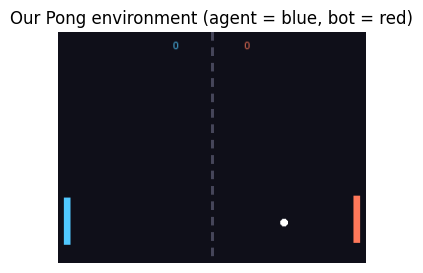

In [ ]:
check_env(PongEnv(), warn=True)
print("check_env passed")

def random_policy(obs):
    return np.random.randint(3)

def tracker_policy(obs):
    d = obs[1] - obs[4]
    return 0 if abs(d) < 0.02 else (2 if d > 0 else 1)

env = PongEnv()
obs, _ = env.reset(seed=1)
for _ in range(40):
    obs, *_ = env.step(tracker_policy(obs))
plt.figure(figsize=(4, 3)); plt.imshow(env.render()); plt.axis("off")
plt.title("Our Pong environment (agent = blue, bot = red)"); plt.show()

## 2. Logging and evaluation helpers

* `EpisodeLogger` records, for every finished training episode, the timestep, the (shaped) return and the final score difference. The same wrapper is used for DQN and PPO, so the reward curves are directly comparable.
* `evaluate()` runs the greedy policy for `N_EVAL` test episodes **without reward shaping**, so the evaluation reward is simply the final **score difference** (agent points − opponent points, range −5 … +5).

In [ ]:
class EpisodeLog:
    def __init__(self, name):
        self.name, self.steps = name, 0
        self.timesteps, self.returns, self.score_diffs = [], [], []

class EpisodeLogger(gym.Wrapper):
    def __init__(self, env, log):
        super().__init__(env)
        self.log, self.ep_ret = log, 0.0
    def reset(self, **kwargs):
        self.ep_ret = 0.0
        return self.env.reset(**kwargs)
    def step(self, action):
        obs, r, term, trunc, info = self.env.step(action)
        self.log.steps += 1
        self.ep_ret += r
        if term or trunc:
            self.log.timesteps.append(self.log.steps)
            self.log.returns.append(self.ep_ret)
            self.log.score_diffs.append(info["score_diff"])
        return obs, r, term, trunc, info

def evaluate(policy, n_episodes=N_EVAL, opponent=None, seed0=10_000):
    env = PongEnv(opponent=opponent, hit_reward=0.0)
    rets, wins, lens = [], [], []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=seed0 + i)
        done, ret = False, 0.0
        while not done:
            obs, r, term, trunc, info = env.step(policy(obs))
            ret += r
            done = term or trunc
        rets.append(ret); wins.append(info["score_agent"] > info["score_opp"]); lens.append(env.t)
    return {"mean_reward": np.mean(rets), "std_reward": np.std(rets),
            "win_rate": np.mean(wins), "mean_length": np.mean(lens), "rewards": rets}

for name, pol in [("Random", random_policy), ("Tracker (hand-coded)", tracker_policy)]:
    r = evaluate(pol)
    print(f"{name:22s} reward = {r['mean_reward']:+.2f} ± {r['std_reward']:.2f}   win rate = {r['win_rate']:.0%}")

Random                 reward = -4.65 ± 0.57   win rate = 0%
Tracker (hand-coded)   reward = +2.95 ± 1.69   win rate = 90%


## 3. Agent 1 — Deep Q-Network, implemented from scratch in PyTorch

DQN (Mnih et al., 2013, 2015) approximates the action-value function $Q_\theta(s,a)$ with a neural network and minimises the TD error on mini-batches sampled from a **replay buffer**:

$$L(\theta) = \mathbb{E}_{(s,a,r,s')\sim\mathcal{D}}\Big[\,\ell_{\text{Huber}}\big(y - Q_\theta(s,a)\big)\Big],\qquad
y = r + \gamma\,(1-d)\,Q_{\bar\theta}\big(s',\ \arg\max_{a'} Q_\theta(s',a')\big)$$

We use the **Double DQN** target (van Hasselt et al., 2016): the online network chooses the next action, the **target network** $\bar\theta$ (copied every 1000 steps) evaluates it. This reduces over-estimation of Q-values. Exploration is ε-greedy, with ε decaying linearly from 1.0 to 0.02 over the first 30 % of training.

**Network:** MLP 6 → 128 → 128 → 3 (ReLU).

In [ ]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim=6, n_actions=3, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions))
    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity, obs_dim=6):
        self.capacity, self.ptr, self.size = capacity, 0, 0
        self.obs = np.zeros((capacity, obs_dim), np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), np.float32)
        self.act = np.zeros(capacity, np.int64)
        self.rew = np.zeros(capacity, np.float32)
        self.done = np.zeros(capacity, np.float32)
    def add(self, o, a, r, o2, d):
        i = self.ptr
        self.obs[i], self.act[i], self.rew[i], self.next_obs[i], self.done[i] = o, a, r, o2, d
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)
    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.size, batch_size)
        t = lambda x: torch.as_tensor(x[idx])
        return t(self.obs), t(self.act), t(self.rew), t(self.next_obs), t(self.done)

DQN_CONFIG = dict(
    total_steps=TOTAL_STEPS, gamma=0.99, lr=5e-4, batch_size=64, buffer_size=100_000,
    learning_starts=5_000, train_freq=1, target_update=1_000,
    eps_start=1.0, eps_end=0.02, eps_fraction=0.3, hidden=128,
    hit_reward=0.1, double=True, seed=SEED)

def train_dqn(name, **overrides):
    c = {**DQN_CONFIG, **overrides}
    set_seed(c["seed"])
    rng = np.random.default_rng(c["seed"])
    log = EpisodeLog(name)
    env = EpisodeLogger(PongEnv(hit_reward=c["hit_reward"]), log)
    q = QNetwork(hidden=c["hidden"]).to(DEVICE)
    q_target = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=c["lr"])
    buf = ReplayBuffer(c["buffer_size"])

    obs, _ = env.reset(seed=c["seed"])
    t0 = time.time()
    for step in range(c["total_steps"]):

        frac = min(1.0, step / (c["eps_fraction"] * c["total_steps"]))
        eps = c["eps_start"] + frac * (c["eps_end"] - c["eps_start"])
        if rng.random() < eps:
            a = int(rng.integers(3))
        else:
            with torch.no_grad():
                a = int(q(torch.as_tensor(obs).unsqueeze(0)).argmax(1).item())

        next_obs, r, term, trunc, _ = env.step(a)
        buf.add(obs, a, r, next_obs, float(term))
        obs = next_obs
        if term or trunc:
            obs, _ = env.reset()

        if step >= c["learning_starts"] and step % c["train_freq"] == 0:
            s, a_b, r_b, s2, d = buf.sample(c["batch_size"], rng)
            with torch.no_grad():
                if c["double"]:
                    a2 = q(s2).argmax(1, keepdim=True)
                    q_next = q_target(s2).gather(1, a2).squeeze(1)
                else:
                    q_next = q_target(s2).max(1).values
                y = r_b + c["gamma"] * (1.0 - d) * q_next
            q_sa = q(s).gather(1, a_b.unsqueeze(1)).squeeze(1)
            loss = F.smooth_l1_loss(q_sa, y)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), 10.0)
            opt.step()

        if step % c["target_update"] == 0:
            q_target.load_state_dict(q.state_dict())

        if (step + 1) % 25_000 == 0:
            last = np.mean(log.score_diffs[-10:]) if log.score_diffs else float("nan")
            print(f"[{name}] step {step+1:>7,} | eps {eps:.2f} | last-10 score diff {last:+.2f} | {time.time()-t0:.0f}s")
    q.eval()
    return q, log

def dqn_policy(q):
    def act(obs):
        with torch.no_grad():
            return int(q(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)).argmax(1).item())
    return act

In [ ]:
dqn_model, dqn_log = train_dqn("DQN (γ=0.99)")
torch.save(dqn_model.state_dict(), "results/dqn_pong.pt")

[DQN (γ=0.99)] step  25,000 | eps 0.46 | last-10 score diff -4.00 | 74s
[DQN (γ=0.99)] step  50,000 | eps 0.02 | last-10 score diff +1.50 | 155s
[DQN (γ=0.99)] step  75,000 | eps 0.02 | last-10 score diff +3.00 | 238s
[DQN (γ=0.99)] step 100,000 | eps 0.02 | last-10 score diff +4.40 | 326s
[DQN (γ=0.99)] step 125,000 | eps 0.02 | last-10 score diff +2.40 | 416s
[DQN (γ=0.99)] step 150,000 | eps 0.02 | last-10 score diff +4.10 | 503s


## 4. Agent 2 - Proximal Policy Optimization (Stable-Baselines3)

PPO (Schulman et al., 2017) is an on-policy actor-critic method. It collects rollouts with the current policy $\pi_\theta$, estimates advantages $\hat A_t$ with GAE (λ = 0.95), and maximises the clipped surrogate objective

$$L^{CLIP}(\theta)=\mathbb{E}_t\Big[\min\big(\rho_t(\theta)\hat A_t,\ \operatorname{clip}(\rho_t(\theta),1-\epsilon,1+\epsilon)\hat A_t\big)\Big],\qquad \rho_t(\theta)=\frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}$$

plus a value-function loss and an entropy bonus. Policy and value networks are MLPs 6 → 128 → 128. We use 4 parallel copies of the environment and the **same training budget** and reward function as DQN.

In [ ]:
PPO_CONFIG = dict(learning_rate=3e-4, n_steps=512, batch_size=256, n_epochs=10, gamma=0.99,
                  gae_lambda=0.95, clip_range=0.2, ent_coef=0.01, vf_coef=0.5)
N_ENVS = 4

set_seed(SEED)
ppo_log = EpisodeLog("PPO (γ=0.99)")
vec_env = DummyVecEnv([lambda: EpisodeLogger(PongEnv(hit_reward=0.1), ppo_log) for _ in range(N_ENVS)])
ppo_model = PPO("MlpPolicy", vec_env, policy_kwargs=dict(net_arch=[128, 128]),
                seed=SEED, device=DEVICE, verbose=0, **PPO_CONFIG)
t0 = time.time()
ppo_model.learn(total_timesteps=TOTAL_STEPS)
print(f"PPO trained in {time.time()-t0:.0f}s | last-10 score diff {np.mean(ppo_log.score_diffs[-10:]):+.2f}")
ppo_model.save("results/ppo_pong")

def ppo_policy(model):
    return lambda obs: int(model.predict(obs, deterministic=True)[0])

PPO trained in 89s | last-10 score diff +3.60


## 5. Hyperparameter study

**Main experiment - discount factor γ (DQN).** γ sets how far into the future the agent looks: the effective horizon is roughly $1/(1-\gamma)$ steps - about 10 steps for γ = 0.9, 100 for 0.99 and 1000 for 0.999. One crossing of the ball takes ~30 steps, so a point is decided well after the shot that caused it.

**Extra ablation - reward shaping.** DQN trained with and without the +0.1 bonus for returning the ball (sparse ±1 reward only).

Everything else (network, budget, seed) is kept identical.

In [ ]:
dqn_g090, log_g090 = train_dqn("DQN (γ=0.90)", gamma=0.90)
dqn_g0999, log_g0999 = train_dqn("DQN (γ=0.999)", gamma=0.999)
dqn_noshape, log_noshape = train_dqn("DQN (no shaping)", hit_reward=0.0)

[DQN (γ=0.90)] step  25,000 | eps 0.46 | last-10 score diff -4.50 | 60s
[DQN (γ=0.90)] step  50,000 | eps 0.02 | last-10 score diff +0.80 | 139s
[DQN (γ=0.90)] step  75,000 | eps 0.02 | last-10 score diff +3.50 | 225s
[DQN (γ=0.90)] step 100,000 | eps 0.02 | last-10 score diff +3.90 | 311s
[DQN (γ=0.90)] step 125,000 | eps 0.02 | last-10 score diff +3.20 | 400s
[DQN (γ=0.90)] step 150,000 | eps 0.02 | last-10 score diff +3.50 | 487s
[DQN (γ=0.999)] step  25,000 | eps 0.46 | last-10 score diff -3.10 | 62s
[DQN (γ=0.999)] step  50,000 | eps 0.02 | last-10 score diff +0.30 | 142s
[DQN (γ=0.999)] step  75,000 | eps 0.02 | last-10 score diff +3.50 | 225s
[DQN (γ=0.999)] step 100,000 | eps 0.02 | last-10 score diff +4.40 | 314s
[DQN (γ=0.999)] step 125,000 | eps 0.02 | last-10 score diff +3.10 | 400s
[DQN (γ=0.999)] step 150,000 | eps 0.02 | last-10 score diff +4.30 | 488s
[DQN (no shaping)] step  25,000 | eps 0.46 | last-10 score diff -4.40 | 60s
[DQN (no shaping)] step  50,000 | eps 0.02 |

## 6. Reward curves

Score difference at the end of each training episode vs. timesteps (thin line = raw, thick line = moving average over 10 episodes). We plot the score difference rather than the shaped return so that agents trained with different rewards can be compared on the same scale.

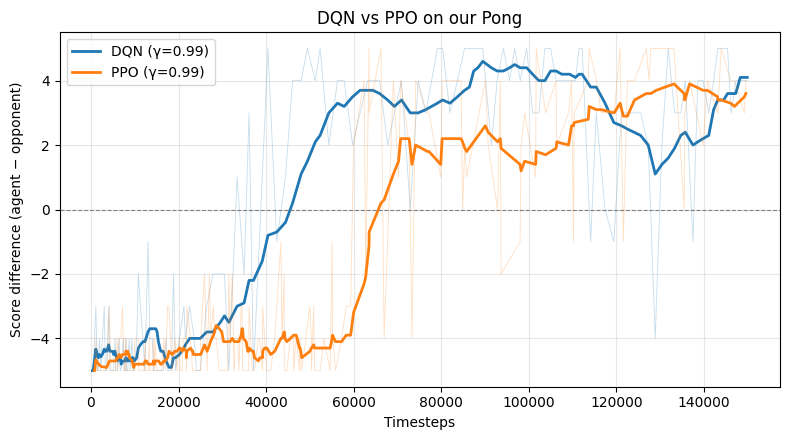

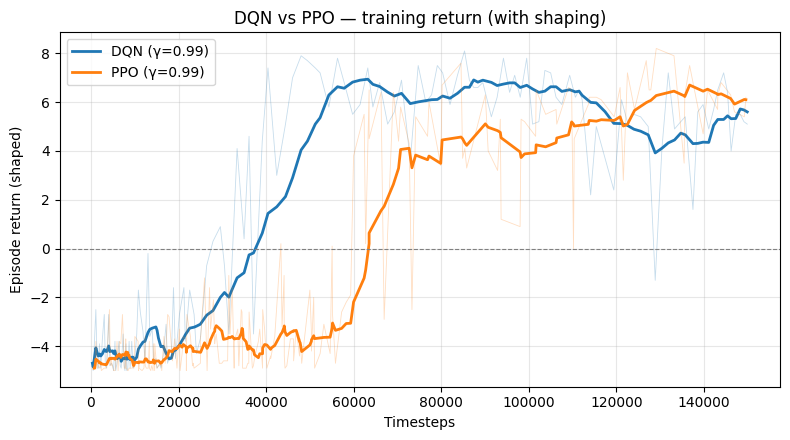

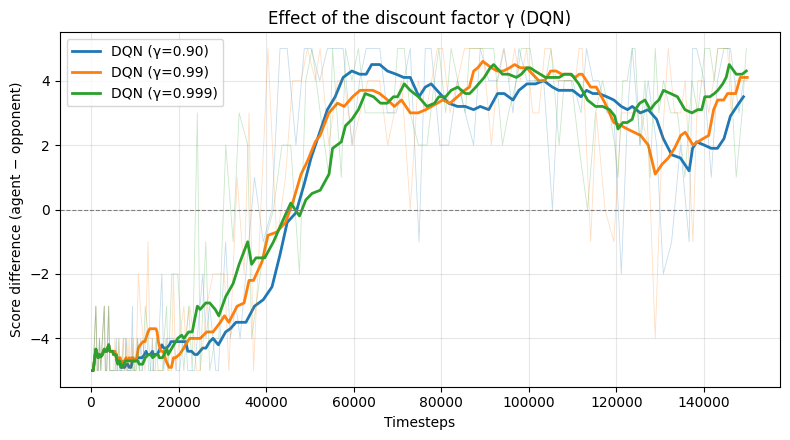

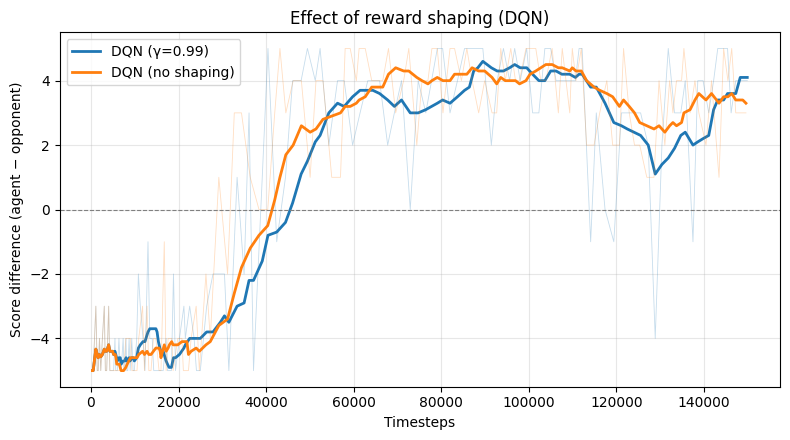

In [ ]:
def smooth(x, w=10):
    x = np.asarray(x, dtype=float)
    return np.array([x[max(0, i - w + 1): i + 1].mean() for i in range(len(x))])

def plot_curves(logs, title, fname, key="score_diffs", ylabel="Score difference (agent − opponent)"):
    plt.figure(figsize=(8, 4.5))
    for log in logs:
        y = getattr(log, key)
        line, = plt.plot(log.timesteps, smooth(y), lw=2, label=log.name)
        plt.plot(log.timesteps, y, lw=0.6, alpha=0.25, color=line.get_color())
    plt.axhline(0, color="grey", lw=0.8, ls="--")
    plt.xlabel("Timesteps"); plt.ylabel(ylabel); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(f"results/{fname}", dpi=150); plt.show()

plot_curves([dqn_log, ppo_log], "DQN vs PPO on our Pong", "curve_dqn_vs_ppo.png")
plot_curves([dqn_log, ppo_log], "DQN vs PPO - training return (with shaping)", "curve_return_dqn_vs_ppo.png",
            key="returns", ylabel="Episode return (shaped)")
plot_curves([log_g090, dqn_log, log_g0999], "Effect of the discount factor γ (DQN)", "curve_gamma.png")
plot_curves([dqn_log, log_noshape], "Effect of reward shaping (DQN)", "curve_shaping.png")

## 7. Evaluation: 20 test episodes per agent

Greedy policies (no exploration), no reward shaping, fixed test seeds that were never used in training. The reward of a test episode is the final score difference (+5 = clean 5:0 win, −5 = 0:5 loss).

,Agent,Mean reward,Std,Win rate,Mean episode length
0,Random,-4.65,0.57,0%,276
1,Tracker (hand-coded),2.95,1.69,90%,1889
2,DQN (γ=0.99),4.25,0.83,100%,955
3,PPO (γ=0.99),1.65,2.24,75%,1386
4,DQN (γ=0.90),4.25,1.22,100%,1639
5,DQN (γ=0.999),4.35,1.35,95%,1260
6,DQN (no shaping),4.15,1.06,100%,907


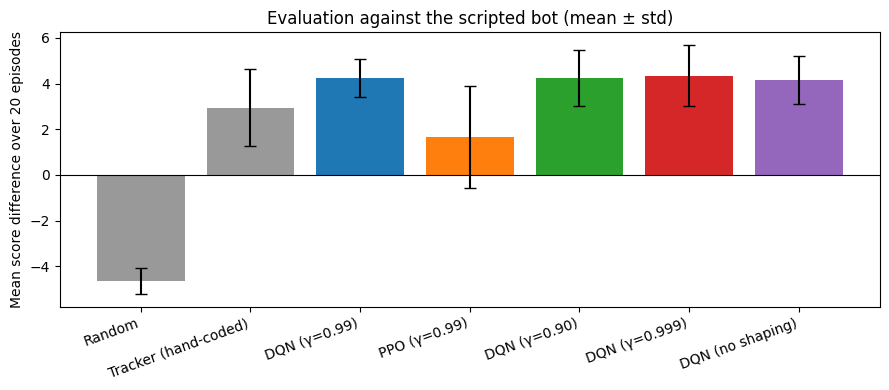

In [ ]:
agents = {
    "Random": random_policy,
    "Tracker (hand-coded)": tracker_policy,
    "DQN (γ=0.99)": dqn_policy(dqn_model),
    "PPO (γ=0.99)": ppo_policy(ppo_model),
    "DQN (γ=0.90)": dqn_policy(dqn_g090),
    "DQN (γ=0.999)": dqn_policy(dqn_g0999),
    "DQN (no shaping)": dqn_policy(dqn_noshape),
}
rows, eval_rewards = [], {}
for name, pol in agents.items():
    r = evaluate(pol)
    eval_rewards[name] = r["rewards"]
    rows.append({"Agent": name, "Mean reward": round(r["mean_reward"], 2), "Std": round(r["std_reward"], 2),
                 "Win rate": f"{r['win_rate']:.0%}", "Mean episode length": int(r["mean_length"])})
eval_df = pd.DataFrame(rows)
eval_df.to_csv("results/evaluation.csv", index=False)
display(eval_df)

plt.figure(figsize=(9, 4))
names = list(eval_rewards)
plt.bar(names, [np.mean(eval_rewards[n]) for n in names], yerr=[np.std(eval_rewards[n]) for n in names],
        capsize=4, color=["#999", "#999", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"])
plt.axhline(0, color="black", lw=0.8)
plt.ylabel(f"Mean score difference over {N_EVAL} episodes"); plt.xticks(rotation=20, ha="right")
plt.title("Evaluation against the scripted bot (mean ± std)")
plt.tight_layout(); plt.savefig("results/evaluation_bar.png", dpi=150); plt.show()

## 8. Tournament: DQN vs. PPO

Now the two trained agents play each other directly. Each agent plays half of the games on the left and half on the right (using the mirrored observation), so neither side has an advantage. Both paddles move at the same speed.

In [ ]:
def tournament(policy_a, policy_b, n_games=40, seed0=50_000):
    diffs, wins_a, wins_b, draws = [], 0, 0, 0
    for g in range(n_games):
        a_left = (g % 2 == 0)
        left, right = (policy_a, policy_b) if a_left else (policy_b, policy_a)
        env = PongEnv(opponent=right, hit_reward=0.0)
        obs, _ = env.reset(seed=seed0 + g)
        done = False
        while not done:
            obs, _, term, trunc, info = env.step(left(obs))
            done = term or trunc
        d = info["score_diff"] if a_left else -info["score_diff"]
        diffs.append(d)
        wins_a += d > 0; wins_b += d < 0; draws += d == 0
    return diffs, wins_a, wins_b, draws

t_diffs, w_dqn, w_ppo, w_draw = tournament(dqn_policy(dqn_model), ppo_policy(ppo_model))
print(f"DQN wins: {w_dqn} | PPO wins: {w_ppo} | draws (time limit): {w_draw}")
print(f"Mean score difference (DQN - PPO): {np.mean(t_diffs):+.2f} ± {np.std(t_diffs):.2f}")
pd.DataFrame({"game": range(len(t_diffs)), "dqn_minus_ppo": t_diffs}).to_csv("results/tournament.csv", index=False)

DQN wins: 37 | PPO wins: 3 | draws (time limit): 0
Mean score difference (DQN − PPO): +3.35 ± 1.70


## 9. Watch the agents (GIFs)

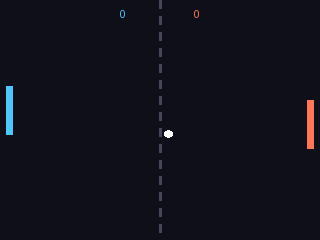

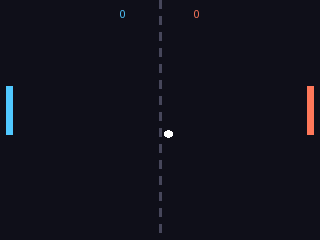

In [ ]:
def record_gif(left_policy, path, opponent=None, max_frames=600, every=2, seed=123):
    env = PongEnv(opponent=opponent, hit_reward=0.0)
    obs, _ = env.reset(seed=seed)
    frames, done, t = [], False, 0
    while not done and len(frames) < max_frames:
        obs, _, term, trunc, _ = env.step(left_policy(obs))
        done = term or trunc
        if t % every == 0:
            frames.append(Image.fromarray(env.render()))
        t += 1
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=40, loop=0)
    return path

display(IPImage(filename=record_gif(dqn_policy(dqn_model), "results/dqn_vs_bot.gif")))
display(IPImage(filename=record_gif(dqn_policy(dqn_model), "results/dqn_vs_ppo.gif",
                                    opponent=ppo_policy(ppo_model))))

## 10. Summary

In [ ]:
hp = pd.DataFrame([
    ["Algorithm", "Double DQN (own PyTorch code)", "PPO (Stable-Baselines3)"],
    ["Network", "MLP 6-128-128-3, ReLU", "MLP 6-128-128 (actor & critic)"],
    ["Training timesteps", f"{TOTAL_STEPS:,}", f"{TOTAL_STEPS:,}"],
    ["Discount γ", DQN_CONFIG["gamma"], PPO_CONFIG["gamma"]],
    ["Learning rate", DQN_CONFIG["lr"], PPO_CONFIG["learning_rate"]],
    ["Batch size", DQN_CONFIG["batch_size"], PPO_CONFIG["batch_size"]],
    ["Replay buffer / rollout", f"{DQN_CONFIG['buffer_size']:,}", f"{PPO_CONFIG['n_steps']} × {N_ENVS} envs"],
    ["Target update / epochs", f"every {DQN_CONFIG['target_update']} steps", f"{PPO_CONFIG['n_epochs']} epochs"],
    ["Exploration", "ε: 1.0 → 0.02 (30 %)", f"entropy coef {PPO_CONFIG['ent_coef']}"],
    ["Other", "Huber loss, grad clip 10", "clip 0.2, GAE λ 0.95"],
], columns=["", "DQN", "PPO"])
hp.to_csv("results/hyperparameters.csv", index=False)
display(hp)
display(eval_df)
print(f"Tournament DQN vs PPO: {w_dqn}-{w_ppo} (draws {w_draw}), mean diff {np.mean(t_diffs):+.2f}")

!zip -qr results.zip results
print("All figures, tables, models and GIFs are in results/ and results.zip")

,,DQN,PPO
0,Algorithm,Double DQN (own PyTorch code),PPO (Stable-Baselines3)
1,Network,"MLP 6-128-128-3, ReLU",MLP 6-128-128 (actor & critic)
2,Training timesteps,"150,000","150,000"
3,Discount γ,0.99,0.99
4,Learning rate,0.0005,0.0003
5,Batch size,64,256
6,Replay buffer / rollout,"100,000",512 × 4 envs
7,Target update / epochs,every 1000 steps,10 epochs
8,Exploration,ε: 1.0 → 0.02 (30 %),entropy coef 0.01
9,Other,"Huber loss, grad clip 10","clip 0.2, GAE λ 0.95"


,Agent,Mean reward,Std,Win rate,Mean episode length
0,Random,-4.65,0.57,0%,276
1,Tracker (hand-coded),2.95,1.69,90%,1889
2,DQN (γ=0.99),4.25,0.83,100%,955
3,PPO (γ=0.99),1.65,2.24,75%,1386
4,DQN (γ=0.90),4.25,1.22,100%,1639
5,DQN (γ=0.999),4.35,1.35,95%,1260
6,DQN (no shaping),4.15,1.06,100%,907


Tournament DQN vs PPO: 37-3 (draws 0), mean diff +3.35
All figures, tables, models and GIFs are in results/ and results.zip
